In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
import pymc as pm
from pymc.pytensorf import collect_default_updates
import numpy as np
import pytensor
import pytensor.tensor as pt
import transition_prior as trans_prior
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: >

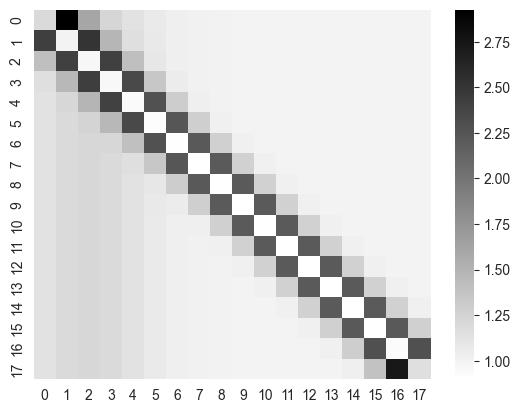

In [42]:
# Some Constants for this minimal example
alphabet = list("abcdefghjklmnopqrs")

# Some informative priors from domain knowledge for this musical sequences
alpha = np.full(len(alphabet), 1)
alpha[4:8 + 1] = 2

beta = trans_prior.TransitionPrior(len(alphabet))
beta.prefer_small_intervals(5,1) 
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
beta = beta.get_beta()

sns.heatmap(beta, cmap="binary")

In [45]:
def build_model(x_0_obs, x_t_obs, lengths_obs, **kwargs):
    with pm.Model() as model:
        pi = pm.Dirichlet("pi", a=alpha)
        A = pm.Dirichlet("A", a=beta)
    
        pm.Categorical("x_0", p=pi, observed=x_0_obs)
    
        x_0_reshaped = pt.shape_padleft(x_0_obs)
        x_full = pt.concatenate([x_0_reshaped, x_t_obs], axis=0)
        x_tm1 = x_full[:-1]
        x_t = x_full[1:]
    
        # Mask for variable length
        t_idx = pt.arange(x_t_obs.shape[0])
        mask = t_idx[:, None] < lengths_obs[None, :]
    
        valid_x_tm1 = x_tm1[mask]
        valid_x_t = x_t[mask]
    
        pm.Categorical("transitions", p=A[valid_x_tm1], observed=valid_x_t)
    return model

In [94]:
import pandas as pd

GS = pd.read_csv("data_gs.csv")
data = GS[["volpiano_pitches"]].dropna()
data = data["volpiano_pitches"].to_list()


In [99]:
def number_sequence(sequence, alphabet=alphabet):
    return [alphabet.index(pitch) for pitch in sequence if pitch in alphabet]

def get_observation_data(sequences):
    lengths = [len(seq) - 1 for seq in sequences]
    max_len = max(lengths)
    num_seqs = len(sequences)

    x_0_data = np.array([seq[0] for seq in sequences], dtype=np.int64)
    x_t_data = np.full((max_len, num_seqs), -1, dtype=np.int64)

    for i, seq in enumerate(sequences):
        seq_len = lengths[i]
        x_t_data[:seq_len, i] = seq[1:]

    return x_0_data, x_t_data, np.array(lengths, dtype=np.int64)

def get_valid_indices(clean_sequences):
    return [i for i, seq in enumerate(clean_sequences) if len(seq) > 1]

def prepare_data(raw_sequences, alphabet=alphabet):
    clean_sequences = [number_sequence(seq, alphabet) for seq in raw_sequences]
    valid_indices = get_valid_indices(clean_sequences)

    valid_sequences = [clean_sequences[i] for i in valid_indices][::-1]
    x_0_data, x_t_data, lengths_data = get_observation_data(valid_sequences)

    return {
        "x_0_obs": x_0_data,
        "x_t_obs": x_t_data,
        "lengths_obs": lengths_data
    }

def build_model(x_0_obs, x_t_obs, lengths_obs, num_states, alpha=1.0, beta=1.0):
    with pm.Model() as model:
        pi = pm.Dirichlet("pi", a=np.ones(num_states) * alpha)
        A = pm.Dirichlet("A", a=np.ones((num_states, num_states)) * beta, shape=(num_states, num_states))
    
        pm.Categorical("x_0", p=pi, observed=x_0_obs)
    
        x_0_reshaped = pt.shape_padleft(x_0_obs)
        x_full = pt.concatenate([x_0_reshaped, x_t_obs], axis=0)
        
        x_tm1 = x_full[:-1]
        x_t = x_full[1:]
    
        t_idx = pt.arange(x_t_obs.shape[0])
        mask = t_idx[:, None] < lengths_obs[None, :]
    
        valid_x_tm1 = x_tm1[mask]
        valid_x_t = x_t[mask]
    
        pm.Categorical("transitions", p=A[valid_x_tm1], observed=valid_x_t)
        
    return model

def fit(data_dict, num_states, draws=1000, tune=1000, **kwargs):
    model = build_model(**data_dict, num_states=num_states)
    with model:
        trace = pm.sample(draws=draws, tune=tune, **kwargs)
    return trace

def fit_from_raw(raw_sequences, alphabet=alphabet, draws=1000, tune=3000, **kwargs):
    data_dict = prepare_data(raw_sequences, alphabet)
    num_states = len(alphabet)
    return fit(data_dict=data_dict, num_states=num_states, draws=draws, tune=tune, **kwargs)


print(prepare_data(data)["x_t_obs"].shape)

(428, 161)


In [100]:
trace = fit_from_raw(data)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [pi, A]


Output()

Sampling 4 chains for 3_000 tune and 1_000 draw iterations (12_000 + 4_000 draws total) took 1490 seconds.


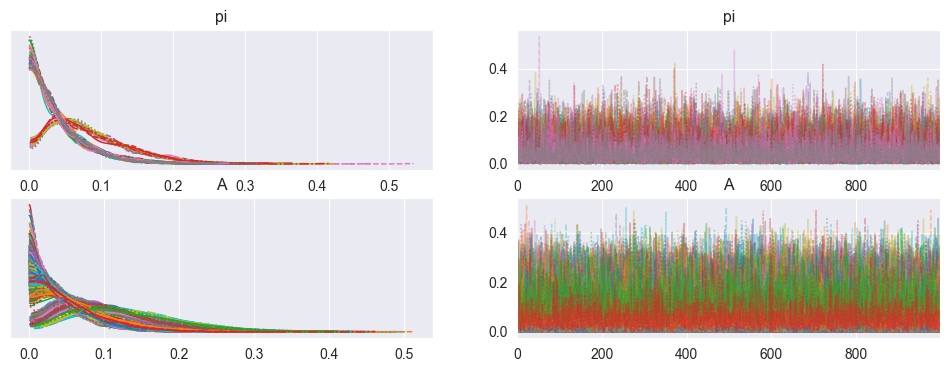

In [54]:
import arviz as az
az.plot_trace(trace, compact=True);

In [59]:
def plot_normalized_histogram(ax, samples, bins, color='teal', alpha=0.8):
    counts, bin_edges = np.histogram(samples, bins=bins, density=True)

    max_count = np.max(counts)
    if max_count > 0:
        counts = counts / max_count

    ax.fill_between(bin_edges[:-1], counts, step="post", color=color, alpha=alpha, linewidth=0)
    ax.axhline(0, color='white', alpha=0.1, linewidth=1)

def style_cell_axes(ax, i, j, v_size, alphabet_list):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.1)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    if j == 0:
        ax.set_ylabel(alphabet_list[i], rotation=0, labelpad=12, fontweight='bold', va='center')
    if i == v_size - 1:
        ax.set_xlabel(alphabet_list[j], fontweight='bold')
        
V = len(alphabet)

d = trace.posterior["A"].stack(samples=("chain", "draw")).values
d

array([[[8.62165440e-02, 8.05971987e-02, 4.15506792e-02, ...,
         8.08853968e-03, 6.48847067e-02, 4.65471326e-02],
        [3.18605074e-02, 9.48929166e-02, 1.94203481e-01, ...,
         1.69296949e-01, 1.17847617e-01, 1.98399722e-01],
        [1.93958675e-01, 5.99036665e-02, 9.62195392e-02, ...,
         5.58370553e-02, 3.17427906e-02, 1.41965801e-01],
        ...,
        [2.08190181e-02, 1.57550315e-02, 1.73353673e-02, ...,
         1.20643855e-01, 9.26453846e-03, 1.88856343e-02],
        [2.90971166e-02, 2.31636417e-02, 2.19829812e-02, ...,
         3.14802560e-02, 4.70332585e-02, 4.61777465e-02],
        [1.38008495e-02, 1.32352636e-02, 1.03982480e-02, ...,
         1.43850464e-02, 2.40183624e-02, 1.02516765e-02]],

       [[1.61869848e-02, 2.16003947e-02, 3.61377649e-01, ...,
         5.18423523e-02, 2.50958687e-01, 4.29827047e-02],
        [2.24784573e-02, 3.25775955e-02, 5.64984963e-02, ...,
         4.86054670e-04, 6.43854241e-03, 1.08244388e-01],
        [7.28324265e-02, 

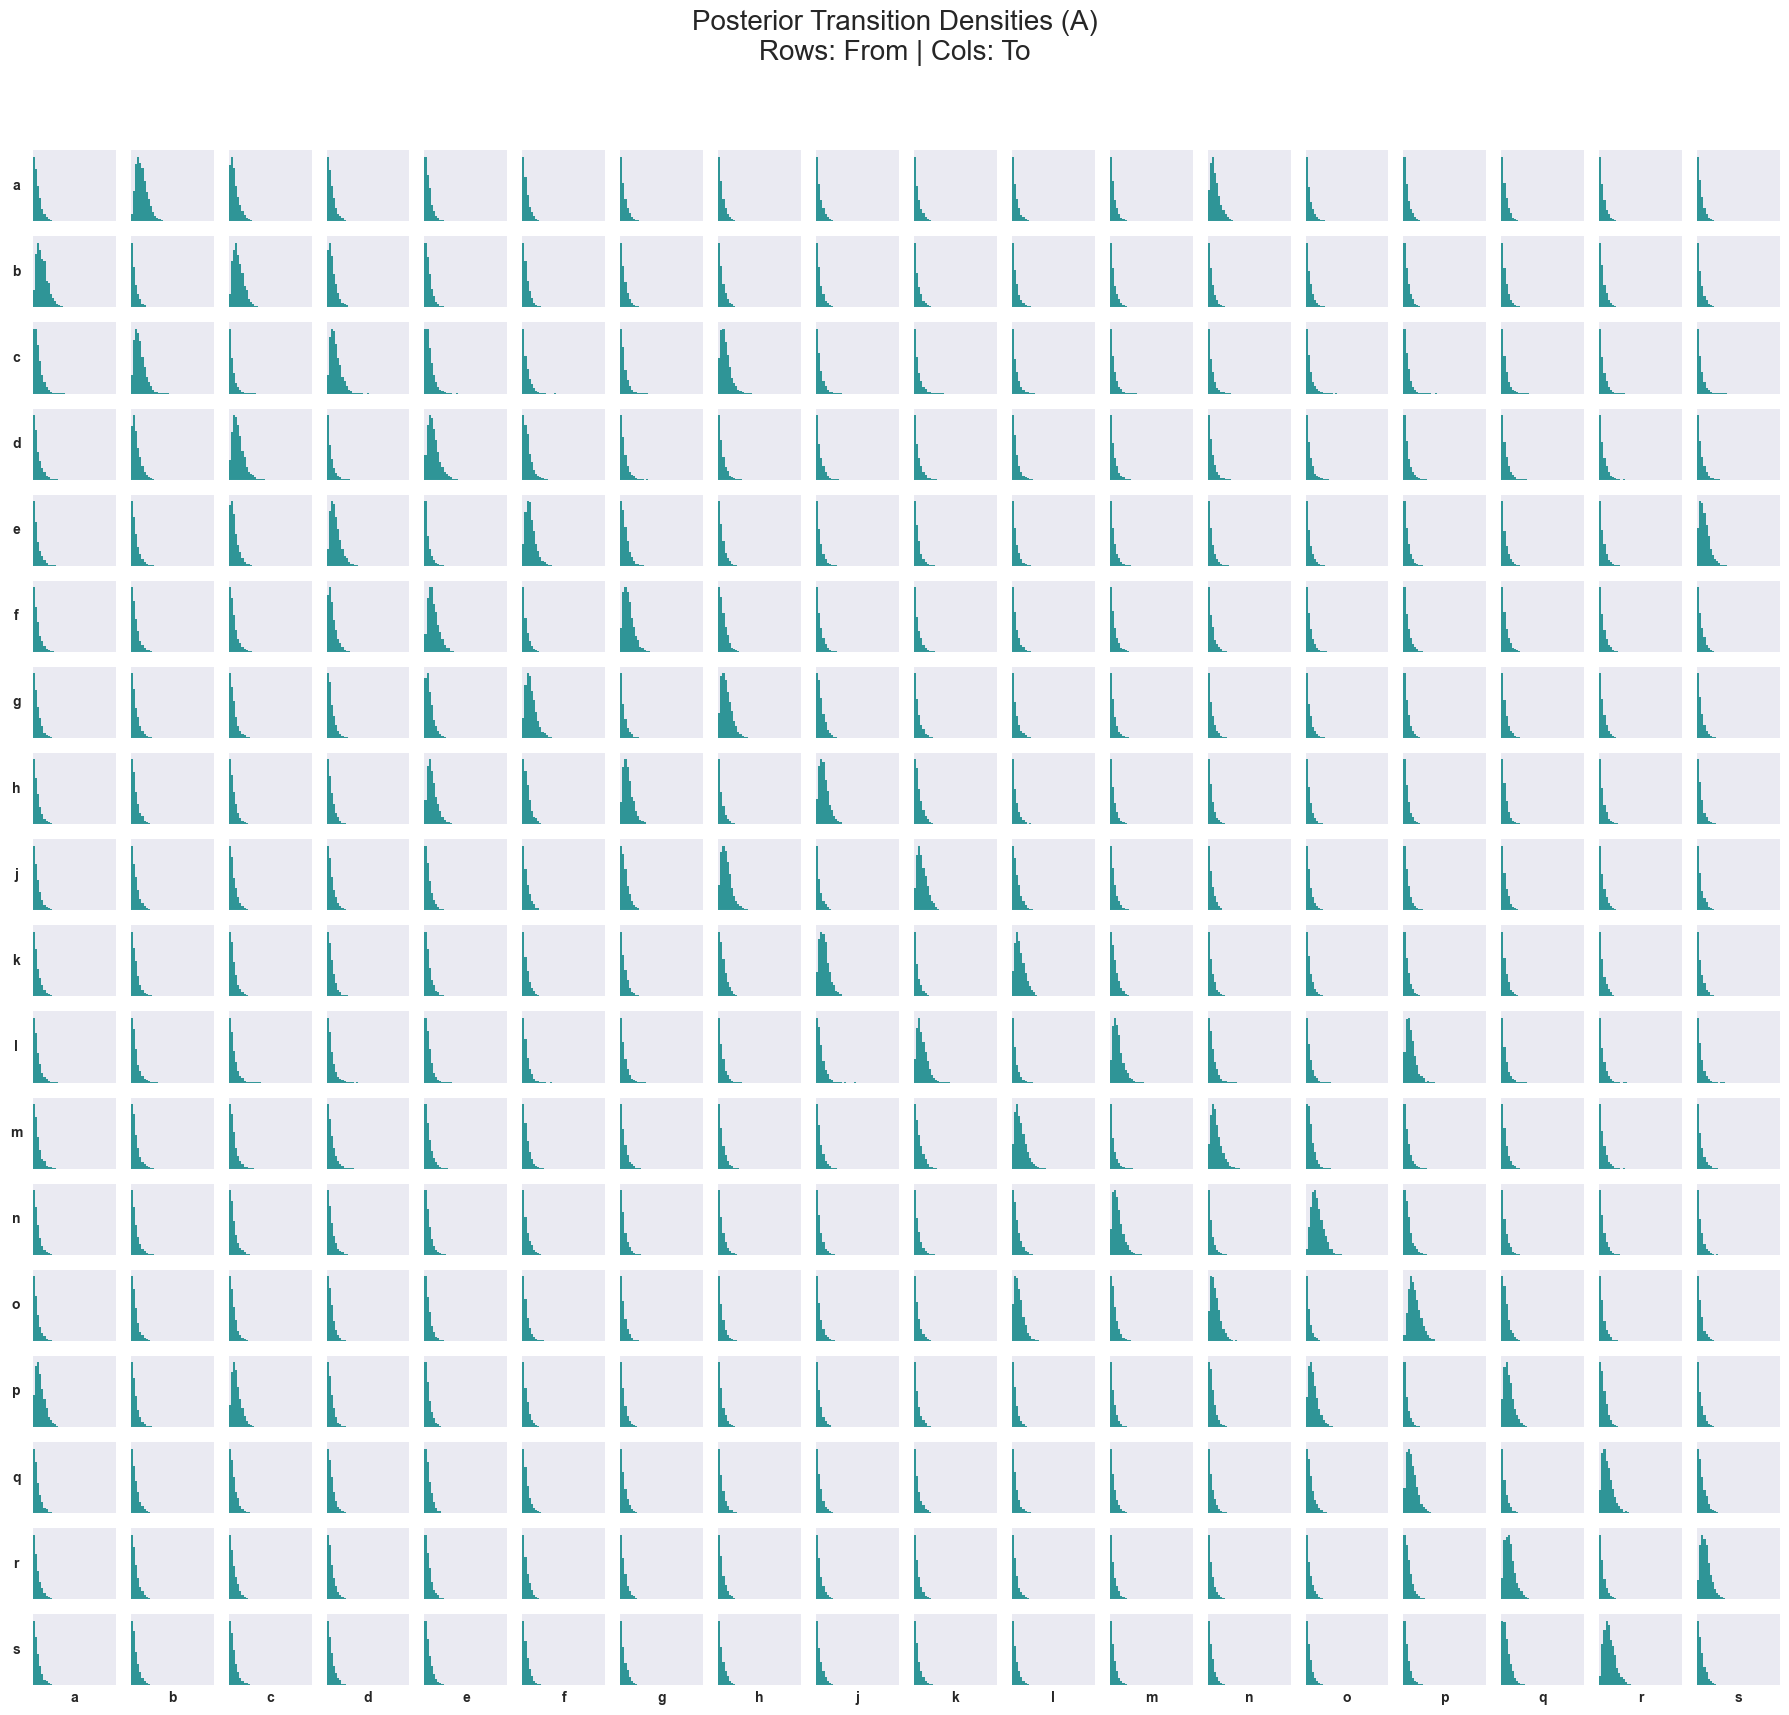

In [61]:
fig, axes = plt.subplots(V, V, figsize=(18, 18), sharex=True, sharey=True)

bins = np.linspace(0, 1, 40)
for i in range(V):
    for j in range(V):
        ax = axes[i, j]
        samples = data[i, j, :]
        plot_normalized_histogram(ax, samples, bins)
        style_cell_axes(ax, i, j, V, alphabet)
plt.suptitle(f"Posterior Transition Densities (A)\nRows: From | Cols: To", fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("posterior.png")